In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import datetime as dt
import numpy as np
from scipy.optimize import minimize

from russian_rates.analysis import (
    align_ruonia_with_key_rate,
    load_rates,
    period_statistics,
    quality_report,
)

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Откройте Jupyter из папки репозитория russian-interest-rate-models.")
DATA_DIR = ROOT / "data" / "processed"

data = load_rates(DATA_DIR)
ruonia = data["ruonia"]
key_rate = data["key_rate"]
zcyc = data["zcyc"]
print(f"Источник: {DATA_DIR}")

Источник: C:\Users\bekishev\Desktop\russian-interest-rate-models\data\processed


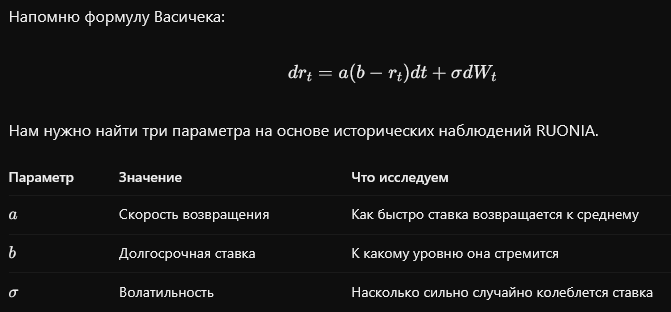

In [2]:
ruonia_wide = ruonia.drop(columns='volume_bln_rub').sort_values(by="date", ascending=True).copy()
ruonia_wide["ruonia_pct"] = ruonia_wide["ruonia_pct"] / 100

In [3]:
ruonia_wide['r_prev'] = ruonia_wide["ruonia_pct"].shift(1)
ruonia_wide['dt'] = ((ruonia_wide['date'] - ruonia_wide['date'].shift(1)).dt.days.dropna().astype(int)) / 365
pairs = ruonia_wide.dropna(subset=["r_prev", "dt"]).copy()
assert (pairs["dt"] > 0).all()

In [4]:
r_prev = pairs["r_prev"].to_numpy(dtype=float)
r_next = pairs["ruonia_pct"].to_numpy(dtype=float)
dt = pairs["dt"].to_numpy(dtype=float)

Логарифмическое правдоподобие


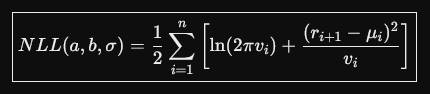

In [5]:
def vasicek_nll(params, r_prev, r_next, dt):
    a, b, sigma = params

    if a <= 0 or sigma <= 0:
        return np.inf

    # экспоненциальный коэффициент возврата
    phi = np.exp(-a * dt)

    # Условное математическое ожидание
    mu = b + (r_prev - b) * phi

    # Условная дисперсия
    var = (sigma**2 * (-np.expm1(-2 * a * dt)) / (2 * a))

    nll = 0.5 * np.sum(
        np.log(2 * np.pi * var)
        + (r_next - mu)**2
    )

    return nll

In [35]:
params = [0.5, 0.1, 0.03]
vasicek_nll(params, r_prev, r_next, dt)

np.float64(-17142.94119856519)

In [36]:
# Поиск оптимальных параметров

# первоначальные приближения
a0 = 0.05
b0 = float(np.mean(r_next))

sigma0 = max(
    0.1,
    float(np.sqrt(np.mean((r_next - r_prev)**2 / dt)))
)

result = minimize(
    fun=vasicek_nll,
    x0=[a0, b0, sigma0],
    args=(r_prev, r_next, dt),
    method="L-BFGS-B",
    bounds=[
        (1e-5, 50), # a > 0
        (None, None), # b без ограничений
        (1e-6, None), # sigma > 0
    ]
)

if not result.success:
    raise RuntimeError(result.message)

a, b, sigma = result.x

In [37]:
# Период полувозврата
half_life = np.log(2) / a

print(f"Half-life: {half_life:.3f} года")
print(f"Half-life: {half_life * 12 :.1f} месяцев")

Half-life: 0.014 года
Half-life: 0.2 месяцев
